<div style="background:linear-gradient(120deg,#062937,#0b6664);border-radius:22px;padding:32px;color:#f2fffd">
<h1 style="color:#f2fffd;font-size:38px">🎯 YouSights</h1>
<h3 style="color:#a9f6e7">Audience Intelligence · Offline Presentation Notebook</h3>
<p style="color:#d0f4ed">Real dataset processing • Actual baseline ML predictions • 4 generated charts • No login / YouTube URL / API key required</p>
</div>

### What this notebook demonstrates
This is a **fully self-contained teaching demo** of YouSights, aligned with the NLP labs: data preparation, text vectorization, model predictions, validation, slice analysis, and visualization. The 48 YouTube-style comments below are **synthetic**, and their reference sentiment labels are **manually annotated example labels**. A TF-IDF + Logistic Regression **baseline model is actually trained and evaluated** below; its test predictions are calculated by code, not hard-coded. This demo is **not evidence of performance on real YouTube traffic**.

**Live application:** The companion Streamlit web app uses a pretrained multilingual Transformer (XLM-T) on the supplied text, and can accept actual comments when a data source is provided. The notebook's baseline is intentionally lightweight so the instructor can see saved results without downloading models.

## 1 · Imports & example dataset
No input prompts and no external data access. All charts are computed from the labeled example comments.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_recall_fscore_support
from IPython.display import display

PALETTE = {"positive":"#17cfa9", "neutral":"#eebd63", "negative":"#fa6b82"}
BG="#081f2d"; FG="#ebfffa"; MUTED="#a8cbd0"
DEMO_DATA = [{'Comment': 'شرحك ممتاز واستفدت كثير', 'GoldSentiment': 'positive', 'Likes': 6}, {'Comment': 'المونتاج جدا مرتب والفيديو جميل', 'GoldSentiment': 'positive', 'Likes': 19}, {'Comment': 'الترجمة ممتازة وشكرا لكم', 'GoldSentiment': 'positive', 'Likes': 32}, {'Comment': 'تجربة جميلة وأفكار مفيدة', 'GoldSentiment': 'positive', 'Likes': 11}, {'Comment': 'الفيديو مرررة مفيد', 'GoldSentiment': 'positive', 'Likes': 24}, {'Comment': 'عمل رائع واستمر في الإبداع', 'GoldSentiment': 'positive', 'Likes': 3}, {'Comment': 'الصوت واضح جدا اليوم', 'GoldSentiment': 'positive', 'Likes': 16}, {'Comment': 'شكرا على المعلومات القيمة', 'GoldSentiment': 'positive', 'Likes': 29}, {'Comment': 'Great explanation, thanks!', 'GoldSentiment': 'positive', 'Likes': 8}, {'Comment': 'Love the editing and transitions', 'GoldSentiment': 'positive', 'Likes': 21}, {'Comment': 'The camera quality looks fantastic', 'GoldSentiment': 'positive', 'Likes': 0}, {'Comment': 'Very informative and easy to understand', 'GoldSentiment': 'positive', 'Likes': 13}, {'Comment': 'The tutorial is amazing', 'GoldSentiment': 'positive', 'Likes': 26}, {'Comment': 'Fantastic video, keep going!', 'GoldSentiment': 'positive', 'Likes': 5}, {'Comment': 'I really enjoyed this detailed review', 'GoldSentiment': 'positive', 'Likes': 18}, {'Comment': 'Great work, the sound is crystal clear', 'GoldSentiment': 'positive', 'Likes': 31}, {'Comment': 'متى ينزل الجزء الثاني؟', 'GoldSentiment': 'neutral', 'Likes': 1}, {'Comment': 'كم سعر الكاميرا المستخدمة؟', 'GoldSentiment': 'neutral', 'Likes': 14}, {'Comment': 'الفيديو مدته عشر دقائق', 'GoldSentiment': 'neutral', 'Likes': 27}, {'Comment': 'ممكن اسم البرنامج؟', 'GoldSentiment': 'neutral', 'Likes': 6}, {'Comment': 'من وين اشتريت المايك؟', 'GoldSentiment': 'neutral', 'Likes': 19}, {'Comment': 'هل عندك فيديو ثاني عن الموضوع؟', 'GoldSentiment': 'neutral', 'Likes': 32}, {'Comment': 'الموضوع يتكلم عن التصوير', 'GoldSentiment': 'neutral', 'Likes': 11}, {'Comment': 'وين رابط المنتج؟', 'GoldSentiment': 'neutral', 'Likes': 24}, {'Comment': 'When is part two coming out?', 'GoldSentiment': 'neutral', 'Likes': 3}, {'Comment': 'What camera are you using?', 'GoldSentiment': 'neutral', 'Likes': 16}, {'Comment': 'The video is ten minutes long', 'GoldSentiment': 'neutral', 'Likes': 29}, {'Comment': 'Can you share the software name?', 'GoldSentiment': 'neutral', 'Likes': 8}, {'Comment': 'Where can I find the source code?', 'GoldSentiment': 'neutral', 'Likes': 21}, {'Comment': 'Which microphone did you use?', 'GoldSentiment': 'neutral', 'Likes': 0}, {'Comment': 'I watched this on my laptop', 'GoldSentiment': 'neutral', 'Likes': 13}, {'Comment': 'Is there an English version?', 'GoldSentiment': 'neutral', 'Likes': 26}, {'Comment': 'الصوت مو واضح في المقطع', 'GoldSentiment': 'negative', 'Likes': 6}, {'Comment': 'الفيديو طويل وممل', 'GoldSentiment': 'negative', 'Likes': 19}, {'Comment': 'التصوير سيء للأسف', 'GoldSentiment': 'negative', 'Likes': 32}, {'Comment': 'ليش الصوت منخفض كذا؟', 'GoldSentiment': 'negative', 'Likes': 11}, {'Comment': 'المحتوى ضعيف وما استفدت', 'GoldSentiment': 'negative', 'Likes': 24}, {'Comment': 'الصوت يقطع كثير للأسف', 'GoldSentiment': 'negative', 'Likes': 3}, {'Comment': 'الشرح ملخبط وصعب الفهم', 'GoldSentiment': 'negative', 'Likes': 16}, {'Comment': 'الاضاءة سيئة في هذا الفيديو', 'GoldSentiment': 'negative', 'Likes': 29}, {'Comment': 'The microphone is too quiet', 'GoldSentiment': 'negative', 'Likes': 8}, {'Comment': 'This video was a waste of time', 'GoldSentiment': 'negative', 'Likes': 21}, {'Comment': 'Subtitles are out of sync', 'GoldSentiment': 'negative', 'Likes': 0}, {'Comment': 'Sound quality needs improvement', 'GoldSentiment': 'negative', 'Likes': 13}, {'Comment': 'The explanation is confusing', 'GoldSentiment': 'negative', 'Likes': 26}, {'Comment': 'I cannot hear anything clearly', 'GoldSentiment': 'negative', 'Likes': 5}, {'Comment': 'The editing makes it hard to follow', 'GoldSentiment': 'negative', 'Likes': 18}, {'Comment': 'This tutorial was disappointing', 'GoldSentiment': 'negative', 'Likes': 31}]
df = pd.DataFrame(DEMO_DATA)
def writing_system(text):
    ar = bool(re.search(r"[\u0600-\u06ff]", text))
    en = bool(re.search(r"[A-Za-z]", text))
    return "Mixed" if ar and en else "Arabic" if ar else "English" if en else "Other"
df["WritingSystem"] = df["Comment"].apply(writing_system)
df["WordCount"] = df["Comment"].str.split().str.len()
print(f"Loaded {len(df)} SYNTHETIC, manually-labeled comments for demonstration only.")
display(df.head(8))

Loaded 48 SYNTHETIC, manually-labeled comments for demonstration only.


,Comment,GoldSentiment,Likes,WritingSystem,WordCount
0,شرحك ممتاز واستفدت كثير,positive,6,Arabic,4
1,المونتاج جدا مرتب والفيديو جميل,positive,19,Arabic,5
2,الترجمة ممتازة وشكرا لكم,positive,32,Arabic,4
3,تجربة جميلة وأفكار مفيدة,positive,11,Arabic,4
4,الفيديو مرررة مفيد,positive,24,Arabic,3
5,عمل رائع واستمر في الإبداع,positive,3,Arabic,5
6,الصوت واضح جدا اليوم,positive,16,Arabic,4
7,شكرا على المعلومات القيمة,positive,29,Arabic,4


## 2 · Actual machine-learning baseline (Lab 3A + Lab 6)
TF-IDF creates features. Logistic Regression is fit **only on the training split**. We then predict a held-out test split and calculate real metrics. These results are small-sample demo metrics, **not performance claims for the deployed Transformer**.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    df["Comment"], df["GoldSentiment"], test_size=0.25,
    stratify=df["GoldSentiment"], random_state=42
)
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2,5), min_df=1)),
    ("model", LogisticRegression(max_iter=1200, class_weight="balanced", random_state=42))
])
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
confidence = baseline.predict_proba(X_test).max(axis=1)
results = df.loc[X_test.index].copy()
results["Predicted"] = y_pred
results["ModelConfidence"] = confidence
results["Correct"] = results["GoldSentiment"].eq(results["Predicted"])
accuracy = accuracy_score(y_test,y_pred)
macro_f1 = f1_score(y_test,y_pred,average="macro",zero_division=0)
print(f"Train: {len(X_train)} | Held-out test: {len(X_test)}")
print(f"Held-out Accuracy: {accuracy:.1%} | Macro-F1: {macro_f1:.3f}")
print(classification_report(y_test,y_pred,zero_division=0))
display(results[["Comment","GoldSentiment","Predicted","ModelConfidence","Correct"]].sort_values("ModelConfidence").round(3))

Train: 36 | Held-out test: 12
Held-out Accuracy: 33.3% | Macro-F1: 0.306
              precision    recall  f1-score   support

    negative       0.25      0.25      0.25         4
     neutral       0.60      0.75      0.67         4
    positive       0.00      0.00      0.00         4

    accuracy                           0.33        12
   macro avg       0.28      0.33      0.31        12
weighted avg       0.28      0.33      0.31        12



,Comment,GoldSentiment,Predicted,ModelConfidence,Correct
10,The camera quality looks fantastic,positive,negative,0.347,False
11,Very informative and easy to understand,positive,neutral,0.352,False
23,وين رابط المنتج؟,neutral,neutral,0.353,True
20,من وين اشتريت المايك؟,neutral,neutral,0.360,True
44,The explanation is confusing,negative,positive,0.364,False
15,"Great work, the sound is crystal clear",positive,negative,0.370,False
42,Subtitles are out of sync,negative,neutral,0.375,False
38,الشرح ملخبط وصعب الفهم,negative,positive,0.381,False
17,كم سعر الكاميرا المستخدمة؟,neutral,positive,0.386,False
9,Love the editing and transitions,positive,negative,0.401,False


## 3 · Four visualizations
The first two describe the **manually annotated synthetic dataset**. The last two describe **actual held-out predictions** of the baseline. No chart uses invented model predictions.

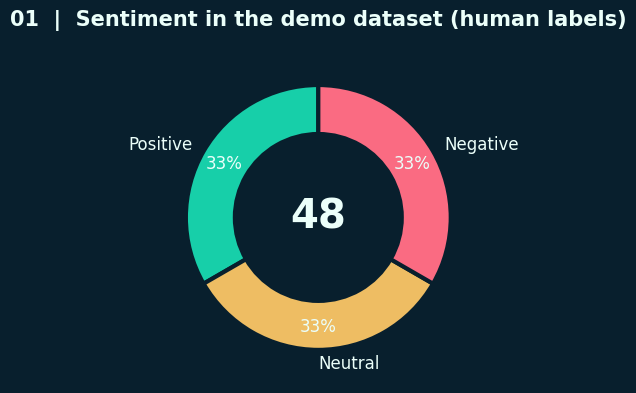

In [3]:
# CHART 1 — Dataset sentiment breakdown
freq=df["GoldSentiment"].value_counts().reindex(["positive","neutral","negative"],fill_value=0)
fig,ax=plt.subplots(figsize=(8,4.3),facecolor=BG)
ax.set_facecolor(BG)
ax.pie(freq.values, labels=["Positive","Neutral","Negative"], startangle=90,
       autopct="%1.0f%%",pctdistance=.82,
       colors=[PALETTE[k] for k in freq.index],
       wedgeprops={"width":.37,"edgecolor":BG,"linewidth":3},
       textprops={"color":FG,"fontsize":12})
ax.text(0,0,str(len(df)),ha="center",va="center",color=FG,fontsize=29,fontweight="bold")
ax.set_title("01  |  Sentiment in the demo dataset (human labels)",color=FG,fontweight="bold",fontsize=15,pad=19)
plt.show()

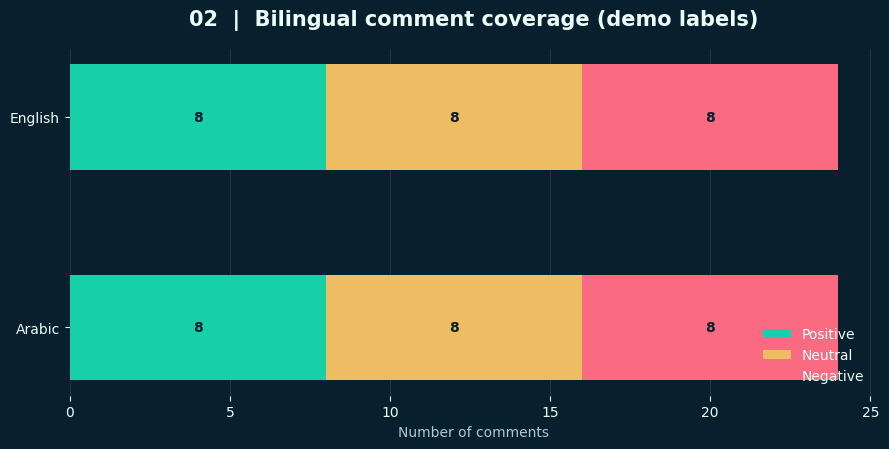

In [4]:
# CHART 2 — Sentiment by writing system
cross=pd.crosstab(df["WritingSystem"],df["GoldSentiment"]).reindex(columns=["positive","neutral","negative"],fill_value=0)
fig,ax=plt.subplots(figsize=(9,4.6),facecolor=BG)
ax.set_facecolor(BG)
left=np.zeros(len(cross))
for k in ["positive","neutral","negative"]:
    v=cross[k].to_numpy()
    bars=ax.barh(cross.index,v,left=left,color=PALETTE[k],label=k.title(),height=.5)
    for b,value in zip(bars,v):
        if value: ax.text(b.get_x()+b.get_width()/2,b.get_y()+b.get_height()/2,str(value),ha="center",va="center",color=BG,fontweight="bold")
    left+=v
ax.set_title("02  |  Bilingual comment coverage (demo labels)",color=FG,fontweight="bold",fontsize=15,pad=17)
ax.set_xlabel("Number of comments",color=MUTED)
ax.tick_params(colors=FG);ax.grid(axis="x",alpha=.1,color=FG);ax.set_axisbelow(True)
for s in ax.spines.values():s.set_visible(False)
leg=ax.legend(frameon=False,loc="lower right",labelcolor=FG)
plt.tight_layout();plt.show()

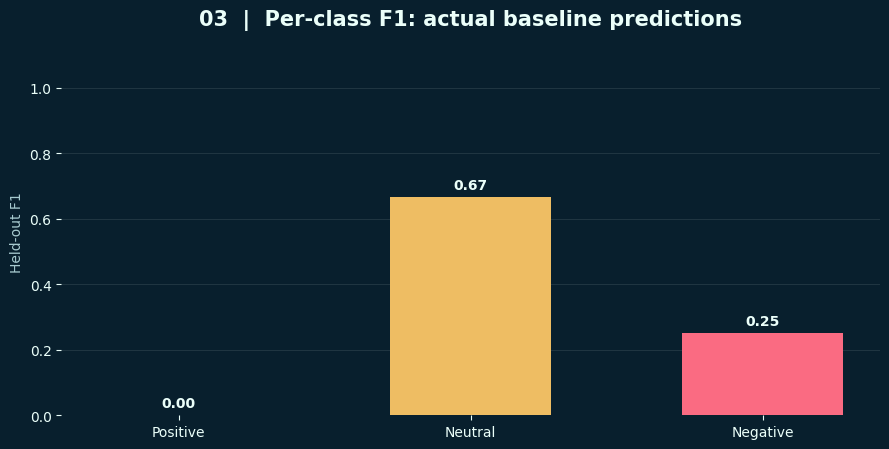

In [5]:
# CHART 3 — REAL baseline model F1 for each sentiment on held-out test comments
labels=["positive","neutral","negative"]
prec,rec,f1_per_class,support=precision_recall_fscore_support(y_test,y_pred,labels=labels,zero_division=0)
fig,ax=plt.subplots(figsize=(9,4.6),facecolor=BG)
ax.set_facecolor(BG)
bar=ax.bar([x.title() for x in labels],f1_per_class,color=[PALETTE[x] for x in labels],width=.55)
for b,v in zip(bar,f1_per_class):ax.text(b.get_x()+b.get_width()/2,v+.025,f"{v:.2f}",ha="center",color=FG,fontweight="bold")
ax.set_ylim(0,1.12);ax.set_ylabel("Held-out F1",color=MUTED)
ax.set_title("03  |  Per-class F1: actual baseline predictions",color=FG,fontweight="bold",fontsize=15,pad=17)
ax.tick_params(colors=FG);ax.grid(axis="y",alpha=.1,color=FG);ax.set_axisbelow(True)
for s in ax.spines.values():s.set_visible(False)
plt.tight_layout();plt.show()

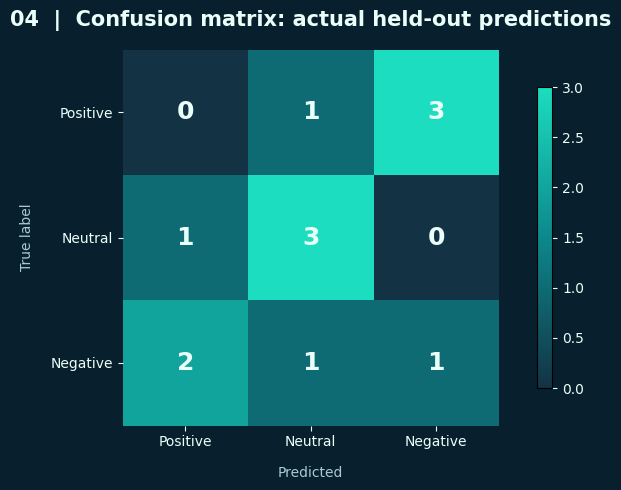

In [6]:
# CHART 4 — REAL confusion matrix on the held-out sample
cm=confusion_matrix(y_test,y_pred,labels=labels)
fig,ax=plt.subplots(figsize=(8,5),facecolor=BG)
ax.set_facecolor(BG)
from matplotlib.colors import LinearSegmentedColormap
cmap=LinearSegmentedColormap.from_list("teal",["#133344","#0c888c","#1cddbf"])
im=ax.imshow(cm,cmap=cmap)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j,i,str(cm[i,j]),ha="center",va="center",color=FG,fontweight="bold",fontsize=18)
ax.set_xticks(range(3),[s.title() for s in labels]);ax.set_yticks(range(3),[s.title() for s in labels])
ax.set_xlabel("Predicted",color=MUTED,labelpad=12);ax.set_ylabel("True label",color=MUTED,labelpad=12)
ax.tick_params(colors=FG)
ax.set_title("04  |  Confusion matrix: actual held-out predictions",color=FG,fontweight="bold",fontsize=15,pad=17)
for s in ax.spines.values():s.set_visible(False)
fig.colorbar(im,ax=ax,shrink=.8).ax.tick_params(colors=FG)
plt.tight_layout();plt.show()

## 4 · Error analysis and reproducible export
A real model can make errors even on this controlled demo set. Examine each wrong prediction rather than pretending all output is correct. The live app uses a different, stronger pretrained Transformer.

In [7]:
errors=results.loc[~results["Correct"],["Comment","GoldSentiment","Predicted","ModelConfidence"]]
print(f"Misclassified held-out comments: {len(errors)} out of {len(results)}")
display(errors.round(3))
output_path="YouSights_Demo_Baseline_Predictions.csv"
results.to_csv(output_path,index=False,encoding="utf-8-sig")
print("Saved:",output_path)

Misclassified held-out comments: 8 out of 12


,Comment,GoldSentiment,Predicted,ModelConfidence
15,"Great work, the sound is crystal clear",positive,negative,0.370
42,Subtitles are out of sync,negative,neutral,0.375
11,Very informative and easy to understand,positive,neutral,0.352
17,كم سعر الكاميرا المستخدمة؟,neutral,positive,0.386
38,الشرح ملخبط وصعب الفهم,negative,positive,0.381
9,Love the editing and transitions,positive,negative,0.401
44,The explanation is confusing,negative,positive,0.364
10,The camera quality looks fantastic,positive,negative,0.347


Saved: YouSights_Demo_Baseline_Predictions.csv


### Submission notes / ملاحظات التسليم
- **Source:** Synthetic YouTube-style comments, manually annotated for the classroom demo. No audience or YouTube API data is claimed.
- **Actual ML processing:** TF-IDF features, fitted Logistic Regression, held-out predictions, F1 and confusion matrix calculated from the model.
- **Visualizations:** All four charts generated from demo labels or real held-out baseline predictions.
- **Production system:** The separately deployed Streamlit application runs a pretrained multilingual Transformer (XLM-T) and optionally fetches actual YouTube comments when given a legitimate API key.
- **To reproduce:** Open in Google Colab, choose **Runtime → Run all**. The four charts are **already embedded** in the saved notebook, so the instructor can also inspect it without running it.